# Exploratory Data Analysis: Singapore Pilot, FY2023

## 1. Load the Cleaned Dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = ROOT / "data/processed/orbis_singapore_fy2023_clean.parquet"

df = pd.read_parquet(DATA_FILE)

COLORS = {
    "Listed": "#355C7D",
    "Unlisted": "#C8A27C"
}

print("Dataset:", DATA_FILE.name)
print("Shape:", df.shape)

display(df.head())

Dataset: orbis_singapore_fy2023_clean.parquet
Shape: (48995, 32)


,Company name Latin alphabet,Inactive,Quoted,branch,OwnData,Woco,country_code,nace4,consolidation_code,bvd_id,...,listing_status,status,Closing date Last avail. yr,closing_date_2023,Closing date 2022,_source_file,listed,assets_usd,log_assets,nace2
0,NVIDIA SINGAPORE PTE LTD,No,No,No,No,No,SG,4652,U1,SG200003831M,...,Unlisted,Active,2026-01-31,2024-01-31,2023-01-31,orbis_sg_fy2023_part1.xlsx,0,6628667999.99975,22.614670,46
1,VITOL ASIA PTE LTD,No,No,No,No,No,SG,4671,U1,SG199001917Z,...,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,0,11426305999.9993,23.159184,46
2,CLOUD NETWORK TECHNOLOGY SINGAPORE PTE. LTD.,No,No,No,No,No,SG,2620,U1,SG201712311G,...,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,0,17839393999.9995,23.604675,26
3,WILMAR INTERNATIONAL LIMITED,No,Yes,No,No,Yes,SG,1042,C1,SG199904785Z,...,Listed,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,1,61808692000.0,24.847310,10
4,GOOGLE ASIA PACIFIC PTE. LTD.,No,No,No,No,Yes,SG,6391,U1,SG200817984R,...,Unlisted,Active,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,0,15045310255.919401,23.434332,63


## 2. Inspect Columns, Data Types, and Recorded Missing Values

In [2]:
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

# Missing values summary
missing_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

display(missing_summary)

Dataset shape: (48995, 32)
<class 'pandas.DataFrame'>
RangeIndex: 48995 entries, 0 to 48994
Data columns (total 32 columns):
 #   Column                                    Non-Null Count  Dtype         
---  ------                                    --------------  -----         
 0   Company name Latin alphabet               48995 non-null  string        
 1   Inactive                                  48995 non-null  string        
 2   Quoted                                    48995 non-null  string        
 3   branch                                    48995 non-null  string        
 4   OwnData                                   48995 non-null  string        
 5   Woco                                      48995 non-null  string        
 6   country_code                              48995 non-null  string        
 7   nace4                                     48995 non-null  string        
 8   consolidation_code                        48995 non-null  string        
 9   bvd_id      

,Data Type,Missing Count,Missing (%)
Company name Latin alphabet,string,0,0.00
Inactive,string,0,0.00
Quoted,string,0,0.00
branch,string,0,0.00
OwnData,string,0,0.00
Woco,string,0,0.00
country_code,string,0,0.00
nace4,string,0,0.00
consolidation_code,string,0,0.00
bvd_id,string,0,0.00


## 3. Data availability by listing status

In [3]:
# Rename columns 

# The cleaned file already has short names (incl. listing_status);
# create the two names used further down
df["consolidation"] = df["consolidation_code"]
df["firm_id"] = df["bvd_id"]


In [4]:
# 3. Listing Status Verification and Data Availability

import pandas as pd

# 3.1 Check listing status
print("Listing Status Counts:")
display(df["listing_status"].value_counts(dropna=False))

# Check for unexpected listing categories
invalid_status = df[~df["listing_status"].isin(["Listed", "Unlisted"])]

print("Invalid listing status:", len(invalid_status))


# 3.2 Data availability by listing status

variables = ["assets_th_usd", "revenue_th_usd", "employees"]

# Ensure financial variables are numeric
for variable in variables:
    df[variable] = pd.to_numeric(df[variable], errors="coerce")

results = []

for status, group in df.groupby("listing_status"):
    for variable in variables:
        results.append({
            "Listing Status": status,
            "Variable": variable,
            "Total Firms": len(group),
            "Available": group[variable].notna().sum(),
            "Missing": group[variable].isna().sum(),
            "Missing (%)": round(group[variable].isna().mean() * 100, 2)
        })

availability_table = pd.DataFrame(results)

display(availability_table)

Listing Status Counts:


listing_status
Unlisted    48499
Listed        496
Name: count, dtype: int64[pyarrow]

Invalid listing status: 0


,Listing Status,Variable,Total Firms,Available,Missing,Missing (%)
0,Listed,assets_th_usd,496,496,0,0.00
1,Listed,revenue_th_usd,496,493,3,0.60
2,Listed,employees,496,267,229,46.17
3,Unlisted,assets_th_usd,48499,48499,0,0.00
4,Unlisted,revenue_th_usd,48499,48187,312,0.64
5,Unlisted,employees,48499,8,48491,99.98


## 4. Financial Data Quality: Zero, Negative, and Implausibly Small Values

1. Missing values: No financial information is reported.
2. Zero values: The firm reports total assets or revenue equal to zero.
3. Negative values: The reported financial amount is below zero.
4. Implausibly small positive values: The firm reports an unusually small amount, such as total assets below USD 1.

In [5]:
# Financial Data Quality
variables = ["assets_th_usd", "revenue_th_usd"]
results = []

for status, group in df.groupby("listing_status"):
    for variable in variables:
        x = group[variable]

        results.append({
            "Listing Status": status,
            "Variable": variable,
            "Total Firms": len(x),
            "Missing": x.isna().sum(),
            "Zero": (x == 0).sum(),
            "Negative": (x < 0).sum(),
            "Positive below USD 1": ((x > 0) & (x < 0.001)).sum(),
            "Valid Positive": (x > 0).sum()
        })

quality = pd.DataFrame(results)

display(quality)

,Listing Status,Variable,Total Firms,Missing,Zero,Negative,Positive below USD 1,Valid Positive
0,Listed,assets_th_usd,496,0,0,0,0,496
1,Listed,revenue_th_usd,496,3,2,0,0,491
2,Unlisted,assets_th_usd,48499,0,531,19,218,47949
3,Unlisted,revenue_th_usd,48499,312,10292,56,116,37839


Total assets: All 496 listed firms have positive assets. Among 48,499 unlisted firms, 531 have zero assets, 19 have negative assets, and 218 have positive assets below USD 1.

Operating revenue: Revenue is missing for 3 listed and 312 unlisted firms. There are also 10,292 unlisted firms with zero revenue.

Conclusion: Total assets is a suitable primary size measure after excluding non-positive values from the log-assets analysis. Revenue can be used for robustness analysis.

In [6]:
import numpy as np

# Keep positive and non-missing assets
eda_assets = df.loc[df["assets_th_usd"] > 0].copy()

# natural log of assets
eda_assets["log_assets"] = np.log(
    eda_assets["assets_th_usd"].astype(float)
)

print("Original observations:", len(df))
print("Positive-asset observations:", len(eda_assets))

display(eda_assets.head())

Original observations: 48995
Positive-asset observations: 48445


,Company name Latin alphabet,Inactive,Quoted,branch,OwnData,Woco,country_code,nace4,consolidation_code,bvd_id,...,Closing date Last avail. yr,closing_date_2023,Closing date 2022,_source_file,listed,assets_usd,log_assets,nace2,consolidation,firm_id
0,NVIDIA SINGAPORE PTE LTD,No,No,No,No,No,SG,4652,U1,SG200003831M,...,2026-01-31,2024-01-31,2023-01-31,orbis_sg_fy2023_part1.xlsx,0,6628667999.99975,15.706914,46,U1,SG200003831M
1,VITOL ASIA PTE LTD,No,No,No,No,No,SG,4671,U1,SG199001917Z,...,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,0,11426305999.9993,16.251429,46,U1,SG199001917Z
2,CLOUD NETWORK TECHNOLOGY SINGAPORE PTE. LTD.,No,No,No,No,No,SG,2620,U1,SG201712311G,...,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,0,17839393999.9995,16.696920,26,U1,SG201712311G
3,WILMAR INTERNATIONAL LIMITED,No,Yes,No,No,Yes,SG,1042,C1,SG199904785Z,...,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,1,61808692000.0,17.939555,10,C1,SG199904785Z
4,GOOGLE ASIA PACIFIC PTE. LTD.,No,No,No,No,Yes,SG,6391,U1,SG200817984R,...,2025-12-31,2023-12-31,2022-12-31,orbis_sg_fy2023_part1.xlsx,0,15045310255.919401,16.526577,63,U1,SG200817984R


## 4.1. Investigate Very Small Positive Financial Values

Count positive assets and revenue below US$1 and inspect their most
common values.

In [7]:
# Values are in thousands of USD:
# 0.001 thousand USD = US$1.

for variable in ["assets_th_usd", "revenue_th_usd"]:
    values = df[variable].astype("float64")

    tiny = values.gt(0) & values.lt(0.001)

    print(f"\n{variable}: positive values below US$1")

    print(
        pd.crosstab(
            df["listing_status"],
            tiny,
        ).rename(columns={
            False: "Other or missing",
            True: "Positive below US$1",
        })
    )

    print("\nMost common tiny values, in thousands of USD:")
    print(values.loc[tiny].value_counts().head(10))


assets_th_usd: positive values below US$1
assets_th_usd   Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48281                  218

Most common tiny values, in thousands of USD:
assets_th_usd
0.000758    93
0.001000    54
0.000738    18
0.000733     8
0.000742     7
0.000751     7
0.000999     6
0.000732     3
0.000739     3
0.001000     3
Name: count, dtype: int64

revenue_th_usd: positive values below US$1
revenue_th_usd  Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48383                  116

Most common tiny values, in thousands of USD:
revenue_th_usd
0.000008    30
0.000010    23
0.000758    11
0.000008     4
0.000739     3
0.000010     3
0.001000     3
0.000733     3
0.000010     3
0.000007     3
Name: count, dtype: int64


## 5. Descriptive Statistics by Listing Status

In [8]:

variables = ["assets_th_usd", "revenue_th_usd"]

results = []

for status, group in df.groupby("listing_status"):
    for variable in variables:

        # Use only positive financial values
        x = group[variable].dropna()
        x = x[x > 0].astype(float)

        results.append({
            "Listing Status": status,
            "Variable": variable,
            "Count": len(x),
            "Mean": x.mean(),
            "Std Dev": x.std(),
            "Minimum": x.min(),
            "P25": x.quantile(0.25),
            "Median": x.median(),
            "P75": x.quantile(0.75),
            "P90": x.quantile(0.90),
            "Maximum": x.max()
        })

summary_table = pd.DataFrame(results)

display(summary_table.round(2))

,Listing Status,Variable,Count,Mean,Std Dev,Minimum,P25,Median,P75,P90,Maximum
0,Listed,assets_th_usd,496,1449629.43,4980913.55,9.94,31417.96,96719.23,565607.18,2801027.37,61808692.0
1,Listed,revenue_th_usd,491,674131.29,4002348.87,4.20,17818.03,61648.72,198372.83,641526.63,67715457.0
2,Unlisted,assets_th_usd,47949,44732.77,607244.11,0.00,154.74,1015.30,7139.32,38747.47,79846617.1
3,Unlisted,revenue_th_usd,37839,64609.06,987442.48,0.00,225.87,1121.48,6265.65,31702.63,83465374.0


### Observations

Listed firms have substantially higher median total assets and operating revenue than unlisted firms in the cleaned Singapore sample. In both groups, mean values greatly exceed medians, indicating strongly right-skewed firm-size distributions. Employee counts are available for 267 listed firms but only 8 unlisted firms. Therefore, employee-based comparisons would rely on a highly selected subset and are not included as a main EDA comparison.

The descriptive statistics for total assets and operating revenue use positive observations, excluding zero, negative and missing values separately for each measure. Consequently, their sample sizes differ. These results are unadjusted for industry, firm age and consolidation status. They describe differences between listed and unlisted firms but do not establish that listing causes larger firm size.

## 6. Distribution of Total Assets and Operating Revenue

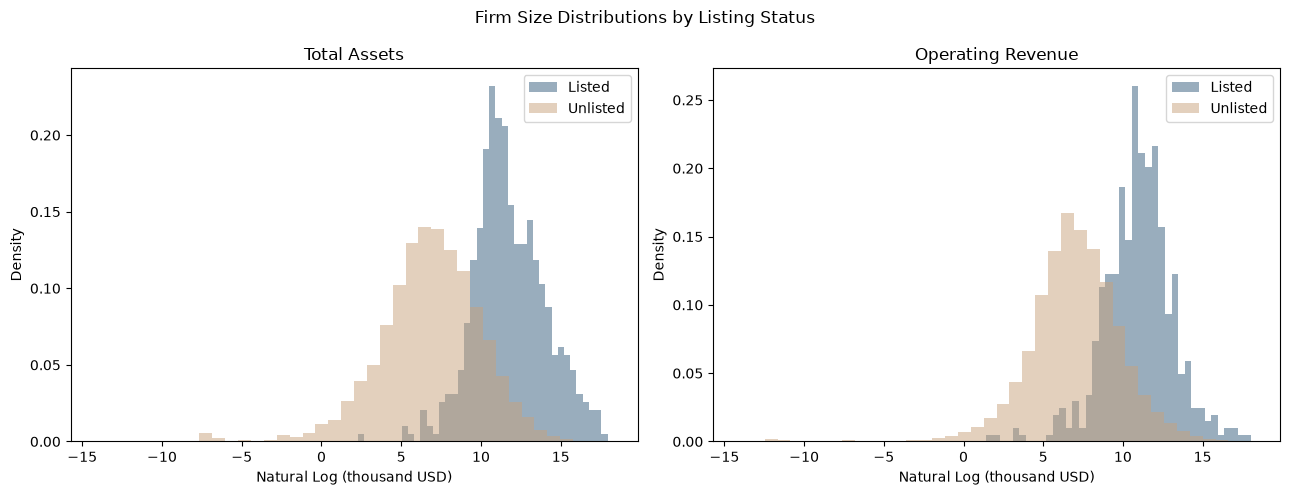

In [9]:
import numpy as np
import matplotlib.pyplot as plt

variables = {
    "assets_th_usd": "Total Assets",
    "revenue_th_usd": "Operating Revenue"
}



COLORS = {
    "Listed": "#355C7D",
    "Unlisted": "#C8A27C"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (variable, title) in zip(axes, variables.items()):

    for status in ["Listed", "Unlisted"]:

        # Select positive values for each group
        x = df.loc[df["listing_status"] == status, variable]
        x = x.dropna()
        x = x[x > 0].astype(float)

        # Natural logarithm
        log_x = np.log(x)

        ax.hist(
            log_x,
            bins=40,
            density=True,
            alpha=0.5,
            color=COLORS[status],
            label=status
        )

    ax.set_title(title)
    ax.set_xlabel("Natural Log (thousand USD)")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("Firm Size Distributions by Listing Status")
plt.tight_layout()
plt.show()

The histograms show that listed firms generally have higher total assets and operating revenue than unlisted firms. Both listed-firm distributions are shifted to the right on the natural-log scale, indicating larger typical firm sizes.

Although the distributions overlap, the concentrations of listed and unlisted firms differ substantially. The unlisted distributions also extend further toward very small positive financial values.

These figures use only positive observations, and the comparisons remain unadjusted for differences in industry, firm age and consolidation status.

## 7. Empirical Cumulative Distribution Function (ECDF) of Log Total Assets

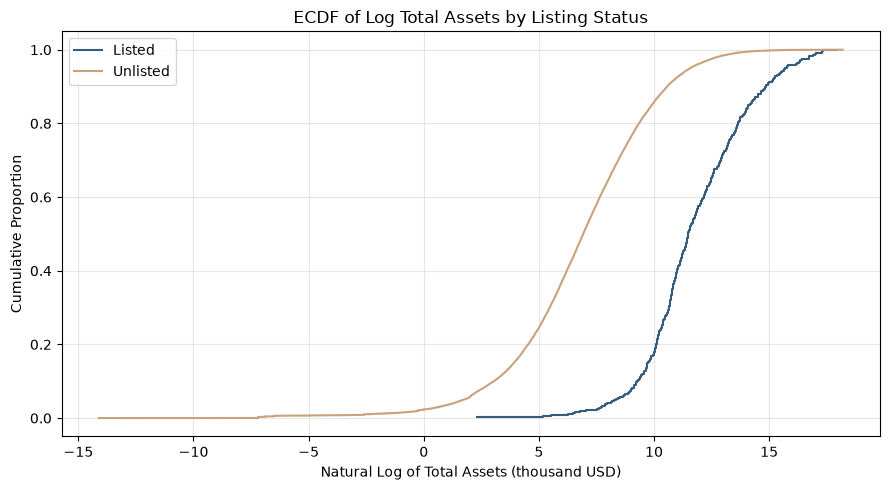

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for status in ["Listed", "Unlisted"]:

    # Get log assets for each group
    x = eda_assets.loc[
        eda_assets["listing_status"] == status,
        "log_assets"
    ].dropna().to_numpy()

    # Sort values from smallest to largest
    x = np.sort(x)

    # Calculate cumulative proportion
    y = np.arange(1, len(x) + 1) / len(x)

    # Plot ECDF
    plt.step(x, y, where="post", label=status, color=COLORS[status])

plt.title("ECDF of Log Total Assets by Listing Status")
plt.xlabel("Natural Log of Total Assets (thousand USD)")
plt.ylabel("Cumulative Proportion")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation: 
In terms of total assets, the Empirical CDF plot clearly shows a move to the right for listed businesses compared to unlisted enterprises. Listed companies are systematically larger over the whole distribution, as evidenced by the fact that they regularly occupy higher percentiles of log-transformed total assets. *Note: These results are only descriptive and do not prove that listing increases company size.

## 8. Boxplot of Log Total Assets by Listing Status

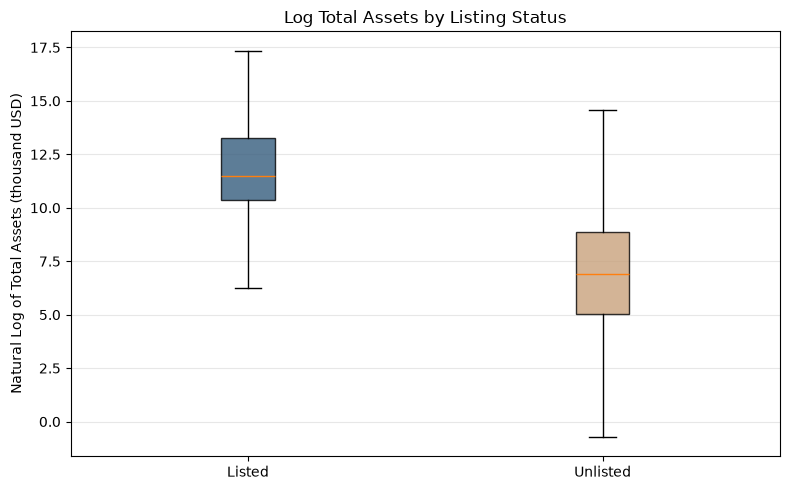

,Listing Status,Count,P25,Median,P75,IQR
0,Listed,496,10.355,11.480,13.246,2.891
1,Unlisted,47949,5.042,6.923,8.873,3.832


In [11]:
import matplotlib.pyplot as plt
import pandas as pd

COLORS = {
    "Listed": "#355C7D",
    "Unlisted": "#C8A27C"
}

# Separate listed and unlisted firms
listed = eda_assets.loc[
    eda_assets["listing_status"] == "Listed",
    "log_assets"
].dropna().astype(float)

unlisted = eda_assets.loc[
    eda_assets["listing_status"] == "Unlisted",
    "log_assets"
].dropna().astype(float)

# Create boxplot
plt.figure(figsize=(8, 5))

bp = plt.boxplot(
    [listed, unlisted],
    tick_labels=["Listed", "Unlisted"],
    patch_artist=True,
    showfliers=False
)

# Apply consistent colors
for patch, status in zip(bp["boxes"], ["Listed", "Unlisted"]):
    patch.set_facecolor(COLORS[status])
    patch.set_alpha(0.8)

# Format graph
plt.title("Log Total Assets by Listing Status")
plt.ylabel("Natural Log of Total Assets (thousand USD)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Boxplot summary statistics
results = []

for status, x in [("Listed", listed), ("Unlisted", unlisted)]:
    q1 = x.quantile(0.25)
    median = x.median()
    q3 = x.quantile(0.75)

    results.append({
        "Listing Status": status,
        "Count": len(x),
        "P25": q1,
        "Median": median,
        "P75": q3,
        "IQR": q3 - q1
    })

boxplot_summary = pd.DataFrame(results)

display(boxplot_summary.round(3))

### Interpretation

The boxplot shows that listed firms have substantially higher median log total assets than unlisted firms. However, unlisted firms have a larger interquartile range, indicating greater variability in the middle 50% of their log-assets distribution.

This suggests that listed firms are generally larger, while unlisted firms exhibit greater relative dispersion in firm size on the logarithmic scale. These differences remain unadjusted for industry, firm age and consolidation status.

## 9. Industry Composition by Listing Status

listing_status,Listed,Unlisted
26 - Electronics manufacturing,7.66,1.08
68 - Real estate,7.66,5.12
46 - Wholesale trade,6.25,19.79
94 - Membership organisations,5.44,0.05
10 - Food manufacturing,4.03,0.97
28 - Machinery manufacturing,3.83,1.21
47 - Retail trade,3.63,3.51
71 - Architecture and engineering,3.43,3.39
86 - Human health activities,2.82,2.55
52 - Warehousing and transport support,2.82,6.59


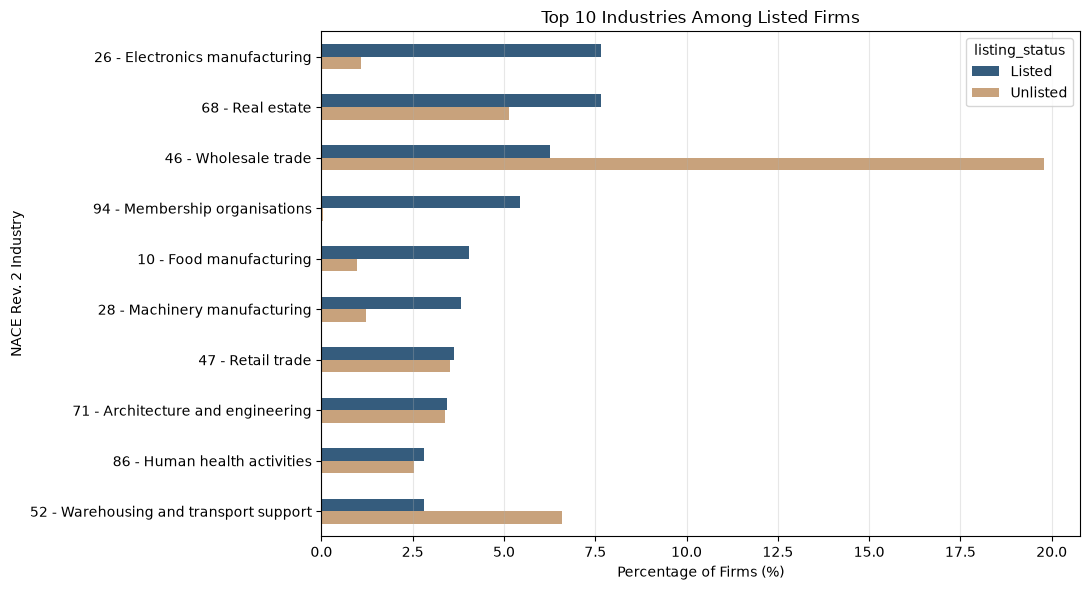

In [12]:
df["nace2"] = (
    df["nace4"]
    .astype("string")
    .str.extract(r"(\d{2})", expand=False)
)

industry_table = pd.crosstab(
    df["nace2"],
    df["listing_status"],
    normalize="columns"
) * 100

# Top 10 industries among listed firms
industry_top10 = (
    industry_table[["Listed", "Unlisted"]]
    .sort_values("Listed", ascending=False)
    .head(10)
    .copy()
)

nace_labels = {
    "10": "Food manufacturing",
    "26": "Electronics manufacturing",
    "28": "Machinery manufacturing",
    "41": "Building construction",
    "46": "Wholesale trade",
    "47": "Retail trade",
    "52": "Warehousing and transport support",
    "56": "Food and beverage services",
    "62": "Computer programming and consultancy",
    "68": "Real estate",
    "70": "Head offices and management consultancy",
    "71": "Architecture and engineering",
    "82": "Office administration and business support",
    "86": "Human health activities",
    "94": "Membership organisations",
}

industry_top10.index = [
    f"{code} - {nace_labels.get(code, 'Check NACE description')}"
    for code in industry_top10.index
]

display(industry_top10.round(2))

ax = industry_top10.plot(
    kind="barh",
    figsize=(11, 6),
    color=[COLORS["Listed"], COLORS["Unlisted"]]
)

ax.invert_yaxis()
ax.set_title("Top 10 Industries Among Listed Firms")
ax.set_xlabel("Percentage of Firms (%)")
ax.set_ylabel("NACE Rev. 2 Industry")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Firm Age and Consolidation Status by Listing Status


We calculate each firm's age in 2023 using:

$$
\text{Firm Age} = 2023 - \text{Incorporation Year}
$$



In [13]:
#  Firm Age

# The cleaned file lost year-only dates (e.g. "2006"), so take the year
# from the original text in the merged file, matched by firm ID
merged_file = ROOT / "data/interim/orbis_singapore_fy2023_merged.parquet"
raw = pd.read_parquet(merged_file, columns=["BvD ID number", "Date of incorporation"])
raw_year = pd.to_numeric(
    raw["Date of incorporation"].astype("string").str.extract(r"(\d{4})", expand=False),
    errors="coerce")
year_by_id = pd.Series(raw_year.to_numpy(), index=raw["BvD ID number"].astype("string"))
df["incorporation_year"] = df["firm_id"].astype("string").map(year_by_id)

#  firm age for FY2023
df["firm_age"] = 2023 - df["incorporation_year"]


# Treat invalid ages as missing
df.loc[df["firm_age"] < 0, "firm_age"] = np.nan

# Create age bands
df["age_band"] = pd.cut(
    df["firm_age"],
    bins=[-1, 4, 9, 19, float("inf")],
    labels=["0-4", "5-9", "10-19", "20+"]
)


display(df[["listing_status", "firm_age", "age_band"]].head())

print("Missing ages:")
print(df.groupby("listing_status")["firm_age"].apply(
    lambda x: x.isna().sum()
))

,listing_status,firm_age,age_band
0,Unlisted,23.0,20+
1,Unlisted,33.0,20+
2,Unlisted,6.0,5-9
3,Listed,24.0,20+
4,Unlisted,15.0,10-19


Missing ages:
listing_status
Listed      0
Unlisted    0
Name: firm_age, dtype: int64


listing_status,Listed,Unlisted
age_band,,
0-4,5.24,34.48
5-9,12.50,22.72
10-19,33.06,23.76
20+,49.19,19.04


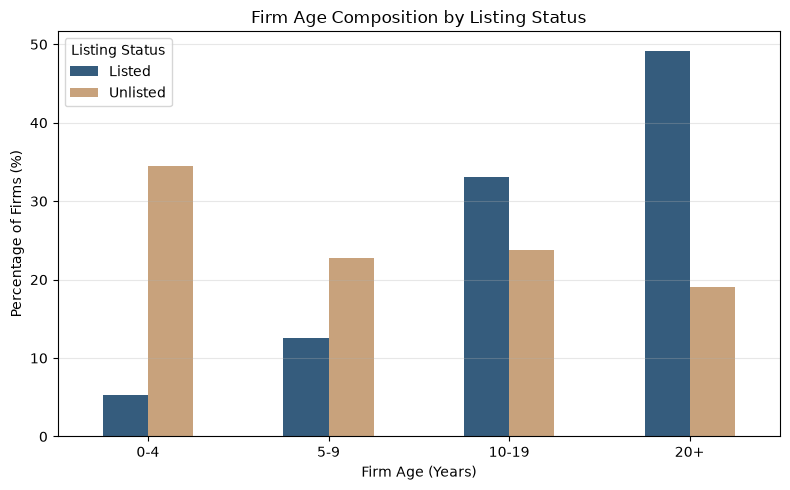

listing_status,Listed,Unlisted
consolidation,,
C1,495,1
C2,1,3085
U1,0,43505
U2,0,1908


In [14]:
# Firm Age Composition

age_table = pd.crosstab(
    df["age_band"],
    df["listing_status"],
    normalize="columns"
) * 100

display(age_table.round(2))

age_table.plot(
    kind="bar",
    figsize=(8, 5),
    color=[COLORS["Listed"], COLORS["Unlisted"]]
)

plt.title("Firm Age Composition by Listing Status")
plt.xlabel("Firm Age (Years)")
plt.ylabel("Percentage of Firms (%)")
plt.xticks(rotation=0)
plt.legend(title="Listing Status")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Consolidation Code Composition

consolidation_table = pd.crosstab(
    df["consolidation"],
    df["listing_status"]
)

display(consolidation_table)

Listed firms are much older than private firms: 49% of listed firms are 20+ years old, compared with 19% of private firms, while only 5% of listed firms are under 5 years old, compared with 34% of private firms. Because older firms tend to be larger, age differences could explain part of the raw size gap, which is why firms are matched on age band and actual age.

In [15]:
# Broad Consolidation Status

df["consolidation_group"] = (
    df["consolidation"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str[0]
)

df["consolidation_group"] = df[
    "consolidation_group"
].where(
    df["consolidation_group"].isin(["C", "U"])
)

broad_table = pd.crosstab(
    df["consolidation_group"],
    df["listing_status"],
    normalize="columns"
) * 100

display(broad_table.round(2))

listing_status,Listed,Unlisted
consolidation_group,,
C,100.0,6.36
U,0.0,93.64


## Missing values among matching variables

In [16]:
# Missing Matching Variables

matching_variables = [
    "nace2",
    "firm_age",
    "age_band",
    "consolidation_group"
]

missing_matching = (
    df.groupby("listing_status")[matching_variables]
    .apply(lambda x: x.isna().sum())
)

display(missing_matching)

,nace2,firm_age,age_band,consolidation_group
listing_status,,,,
Listed,0,0,0,0
Unlisted,0,0,0,0


## 11. Full-Sample Kolmogorov–Smirnov Test (Unadjusted)

**Null hypothesis:**

$$
H_0: F_L(x) = F_U(x) \quad \text{for all } x
$$

**Alternative hypothesis:**

$$
H_1: F_L(x) \neq F_U(x) \quad \text{for some } x
$$

In [17]:
from scipy import stats

listed = eda_assets.loc[
    eda_assets["listing_status"] == "Listed",
    "log_assets"
].dropna().astype(float)

unlisted = eda_assets.loc[
    eda_assets["listing_status"] == "Unlisted",
    "log_assets"
].dropna().astype(float)

ks = stats.ks_2samp(listed, unlisted)

print(f"KS statistic: {ks.statistic:.3f}")
print(f"P-value: {ks.pvalue:.3g}")

KS statistic: 0.700
P-value: 6.96e-242


## 12. EDA Summary and Motivation for Matching

The exploratory analysis shows substantial differences in total assets and operating revenue between listed and unlisted firms in Singapore. Listed firms generally have larger financial values, while the distributions of both groups are strongly right-skewed. However, these comparisons are unadjusted. Differences in industry composition, firm age and consolidation status may explain part of the observed size gap. In particular, the substantial imbalance in consolidation status raises concerns about whether sufficient comparable unlisted firms are available.

The next stage uses nearest-age matching within industry, age-band and consolidation-status groups to construct more comparable samples. The matched analysis will then examine whether size differences persist across the firm-size distribution.

These results are descriptive and do not establish that listing status causes differences in firm size.